# نوت‌بوک ۰۴ اصلاح‌شده — Pearson، CMI، شبکه بیزی TAN و ارزیابی

این نسخه بر اساس نوت‌بوک قبلی پروژه ساخته شده و فایل قبلی را جایگزین نمی‌کند.

**هدف تکلیف:** محاسبه ضریب Pearson، انتخاب و اجرای طبقه‌بند بیزی متناسب با وابستگی ویژگی‌ها، و گزارش عملکرد با Confusion Matrix و معیارهای طبقه‌بندی.

**دامنه این آزمایش:** طبقه‌بندی منبع سؤال:
- کلاس ۰: `CommonsenseQA`
- کلاس ۱: `ARC-Challenge`

ویژگی‌های ورودی:
- `question_words`
- `question_chars`
- `avg_option_words`

ویژگی `option_count` عمداً وارد مدل نمی‌شود؛ چون تعداد گزینه‌ها در دو مجموعه متفاوت است و می‌تواند منبع دیتاست را با یک نشانه مستقیم آشکار کند.

> **محدودیت مهم:** این آزمایش منبع دیتاست را طبقه‌بندی می‌کند؛ تشخیص مستقیم Silent Failure یا درست/غلط بودن پاسخ LLM نیست.

## ۰. اصلاحات روش‌شناختی این نسخه

۱. فرمول CMI به شکل استاندارد تجربی پیاده‌سازی شده است:
\[
I(X_i;X_j\mid Y)=\sum_y P(y)I(X_i;X_j\mid Y=y)
\]
در اینجا \(P(y)\) از فراوانی کلاس‌ها در داده‌ای که ساختار شبکه روی آن یاد گرفته می‌شود محاسبه می‌شود.

۲. نسخه میانگین‌گیری با وزن برابر کلاس‌ها نیز به‌عنوان **تحلیل حساسیت** محاسبه می‌شود؛ اما با CMI استاندارد اشتباه گرفته نمی‌شود.

۳. اثر دو نوع احتمال پیشین کلاس (`balanced` و `empirical`) روی Validation مقایسه می‌شود. برای حفظ هدف مقایسه دو دامنه با وزن برابر، مدل نهایی از prior متوازن استفاده می‌کند و نتیجه prior تجربی صرفاً به‌عنوان تحلیل حساسیت گزارش می‌شود.

۴. تعداد بازه‌ها فقط با Validation انتخاب می‌شود. Test برای انتخاب ویژگی، ساختار، تعداد بازه یا prior استفاده نمی‌شود.

۵. علاوه بر TAN، مدل NBC با همان ویژگی‌ها و prior متوازن به‌عنوان baseline گزارش می‌شود.

In [1]:
# ۱. کتابخانه‌ها و تنظیمات

from pathlib import Path
import io
import os
import zipfile
import json
import warnings
import urllib.request
import subprocess
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report,
)

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("محیط Google Colab شناسایی شد.")
    repo_name = "Detecting-Silent-Failures-of-Uncertainty-Estimators"
    repo_dir = Path(f"/content/{repo_name}")
    # در صورتی که فایل‌های پروژه در مسیر جاری موجود نباشند، کلون خودکار ریپازیتوری
    if not (Path.cwd() / "outputs" / "numeric_features.csv").exists():
        if not repo_dir.exists():
            print("در حال کلون کردن مخزن گیت‌هاب برای دریافت خروجی‌ها و داده‌ها...")
            subprocess.run(
                ["git", "clone", f"https://github.com/mmnsrti/{repo_name}.git"],
                check=False
            )
        if repo_dir.exists() and (repo_dir / "outputs" / "numeric_features.csv").exists():
            os.chdir(repo_dir)
            print(f"مسیر کاری به پوشه مخزن تغییر یافت: {repo_dir}")

RANDOM_STATE = 42
FEATURES = ["question_words", "question_chars", "avg_option_words"]
CLASS_NAMES = {0: "CommonsenseQA", 1: "ARC-Challenge"}
N_BINS_CANDIDATES = [2, 3, 4]
ALPHA = 1.0
FINAL_PRIOR_MODE = "balanced"

print("Libraries imported.")
print("Features:", FEATURES)



Libraries imported.
Features: ['question_words', 'question_chars', 'avg_option_words']


## ۱. بارگذاری داده‌ها

پیش‌نیاز: فایل `outputs/numeric_features.csv` باید از نوت‌بوک ۰۱ ساخته شده باشد.

کد ابتدا مسیرهای محلی و فایل ZIP خروجی‌ها را بررسی می‌کند؛ اگر فایل پیدا نشود، دانلود از مخزن GitHub را امتحان می‌کند. در Google Colab امکان آپلود دستی نیز فراهم است.

In [2]:
# ۲. پیدا کردن فایل numeric_features.csv

def candidate_project_roots():
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path("/content"),
        Path("/content/Detecting-Silent-Failures-of-Uncertainty-Estimators"),
        Path("/content/drive/MyDrive"),
        Path("/content/drive/MyDrive/Detecting Silent Failures of Uncertainty Estimators"),
    ]
    roots, seen = [], set()
    for base in candidates:
        if not base.exists():
            continue
        possible = [base]
        try:
            possible.extend([p for p in base.iterdir() if p.is_dir()])
        except (PermissionError, OSError):
            pass
        for path in possible:
            key = str(path.resolve())
            if key not in seen:
                seen.add(key)
                roots.append(path)
    return roots


def load_numeric_features():
    # الف) مسیرهای محلی
    for root in candidate_project_roots():
        for csv_path in [
            root / "outputs" / "numeric_features.csv",
            root / "numeric_features.csv",
        ]:
            if csv_path.exists():
                print(f"CSV loaded: {csv_path}")
                return pd.read_csv(csv_path), root

        for zip_path in [root / "outputs.zip", root / "outputs" / "outputs.zip"]:
            if zip_path.exists():
                with zipfile.ZipFile(zip_path, "r") as zf:
                    for member in [
                        "outputs/numeric_features.csv",
                        "numeric_features.csv",
                    ]:
                        if member in zf.namelist():
                            print(f"CSV loaded from ZIP: {zip_path}")
                            data = pd.read_csv(io.BytesIO(zf.read(member)))
                            return data, root

    # ب) دانلود از مخزن عمومی پروژه
    github_raw_url = (
        "https://raw.githubusercontent.com/mmnsrti/"
        "Detecting-Silent-Failures-of-Uncertainty-Estimators/"
        "main/outputs/numeric_features.csv"
    )
    try:
        print("Local CSV not found. Trying GitHub download...")
        request = urllib.request.Request(
            github_raw_url, headers={"User-Agent": "Mozilla/5.0"}
        )
        with urllib.request.urlopen(request, timeout=60) as response:
            content = response.read()
        data = pd.read_csv(io.BytesIO(content))
        root = Path.cwd()
        save_path = root / "outputs" / "numeric_features.csv"
        save_path.parent.mkdir(parents=True, exist_ok=True)
        save_path.write_bytes(content)
        print(f"Downloaded CSV saved to: {save_path}")
        return data, root
    except Exception as error:
        print(f"Automatic download failed: {error}")

    # ج) آپلود دستی در Colab
    if IN_COLAB:
        from google.colab import files
        print("Upload numeric_features.csv or outputs.zip:")
        uploaded = files.upload()
        for filename, content in uploaded.items():
            if filename.lower().endswith(".csv"):
                data = pd.read_csv(io.BytesIO(content))
                root = Path.cwd()
                save_path = root / "outputs" / "numeric_features.csv"
                save_path.parent.mkdir(parents=True, exist_ok=True)
                save_path.write_bytes(content)
                return data, root
            if filename.lower().endswith(".zip"):
                with zipfile.ZipFile(io.BytesIO(content)) as zf:
                    for member in [
                        "outputs/numeric_features.csv",
                        "numeric_features.csv",
                    ]:
                        if member in zf.namelist():
                            csv_bytes = zf.read(member)
                            data = pd.read_csv(io.BytesIO(csv_bytes))
                            root = Path.cwd()
                            save_path = root / "outputs" / "numeric_features.csv"
                            save_path.parent.mkdir(parents=True, exist_ok=True)
                            save_path.write_bytes(csv_bytes)
                            return data, root

    raise FileNotFoundError(
        "numeric_features.csv پیدا نشد. ابتدا نوت‌بوک ۰۱ را اجرا کن "
        "یا فایل CSV/outputs.zip را کنار پروژه قرار بده."
    )


df_raw, PROJECT_ROOT = load_numeric_features()
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "classification_v3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw shape:", df_raw.shape)
print("Output directory:", OUTPUT_DIR)

CSV loaded: D:\app\ai\Detecting Silent Failures of Uncertainty Estimators\outputs\numeric_features.csv
Project root: D:\app\ai\Detecting Silent Failures of Uncertainty Estimators
Raw shape: (14692, 8)
Output directory: D:\app\ai\Detecting Silent Failures of Uncertainty Estimators\outputs\classification_v3


## ۲. پاک‌سازی و کنترل تقسیم داده‌ها

نام دیتاست‌ها و splitها یکدست می‌شود. نمونه‌ها به‌صورت تصادفی جابه‌جا نمی‌شوند و split اصلی حفظ می‌شود.

In [3]:
# ۳. استانداردسازی نام دیتاست‌ها و splitها

required_columns = {
    "dataset", "split", "question_words",
    "question_chars", "avg_option_words",
}
missing_columns = required_columns - set(df_raw.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")


def normalize_dataset(value):
    s = str(value).strip().lower().replace("_", "").replace("-", "").replace(" ", "")
    if "commonsenseqa" in s or s == "csqa":
        return "CommonsenseQA"
    if "arc" in s:
        return "ARC-Challenge"
    return np.nan


def normalize_split(value):
    s = str(value).strip().lower()
    mapping = {
        "train": "train",
        "training": "train",
        "validation": "validation",
        "valid": "validation",
        "val": "validation",
        "dev": "validation",
        "test": "test",
    }
    return mapping.get(s, np.nan)


df = df_raw.copy()
df["dataset"] = df["dataset"].map(normalize_dataset)
df["split"] = df["split"].map(normalize_split)

for feature in FEATURES:
    df[feature] = pd.to_numeric(df[feature], errors="coerce")
    df[feature] = df[feature].replace([np.inf, -np.inf], np.nan)

before = len(df)
df = df.dropna(subset=["dataset", "split"] + FEATURES).copy()
df["y"] = df["dataset"].map({
    "CommonsenseQA": 0,
    "ARC-Challenge": 1,
}).astype(int)

print("Rows before cleaning:", before)
print("Rows removed:", before - len(df))
print("Rows after cleaning:", len(df))

split_summary = (
    df.groupby(["split", "dataset"])
      .size()
      .unstack(fill_value=0)
)
display(split_summary)

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()
test_df = df[df["split"] == "test"].copy()

for split_name, part in [
    ("Train", train_df), ("Validation", val_df), ("Test", test_df)
]:
    if part.empty or set(part["y"].unique()) != {0, 1}:
        raise ValueError(f"{split_name} must contain both classes.")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

class_distribution = pd.DataFrame({
    "Train": train_df["y"].value_counts().sort_index(),
    "Validation": val_df["y"].value_counts().sort_index(),
    "Test": test_df["y"].value_counts().sort_index(),
})
class_distribution.index = [CLASS_NAMES[i] for i in class_distribution.index]
display(class_distribution)

Rows before cleaning: 14692
Rows removed: 0
Rows after cleaning: 14692


dataset,ARC-Challenge,CommonsenseQA
split,,
test,1172,1140
train,1119,9741
validation,299,1221


Train: 10860
Validation: 1520
Test: 2312


,Train,Validation,Test
CommonsenseQA,9741,1221,1140
ARC-Challenge,1119,299,1172


## ۳. محاسبه ضریب همبستگی Pearson

Pearson فقط روی Train محاسبه می‌شود؛ هم برای کل Train و هم جداگانه درون هر کلاس. مقدار همبستگی بالا به‌تنهایی استقلال یا وابستگی شرطی را اثبات نمی‌کند.

Pearson — all Train


,question_words,question_chars,avg_option_words
question_words,1.0000,0.9757,0.2833
question_chars,0.9757,1.0000,0.3242
avg_option_words,0.2833,0.3242,1.0000


Pearson — CommonsenseQA


,question_words,question_chars,avg_option_words
question_words,1.0000,0.9677,-0.0371
question_chars,0.9677,1.0000,-0.0554
avg_option_words,-0.0371,-0.0554,1.0000


Pearson — ARC-Challenge


,question_words,question_chars,avg_option_words
question_words,1.0000,0.9834,0.1117
question_chars,0.9834,1.0000,0.1195
avg_option_words,0.1117,0.1195,1.0000


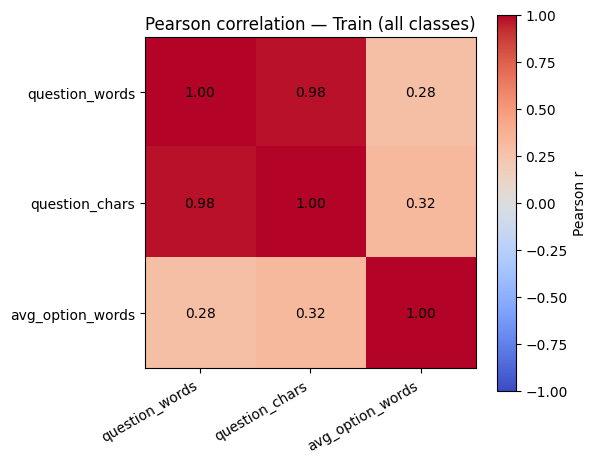

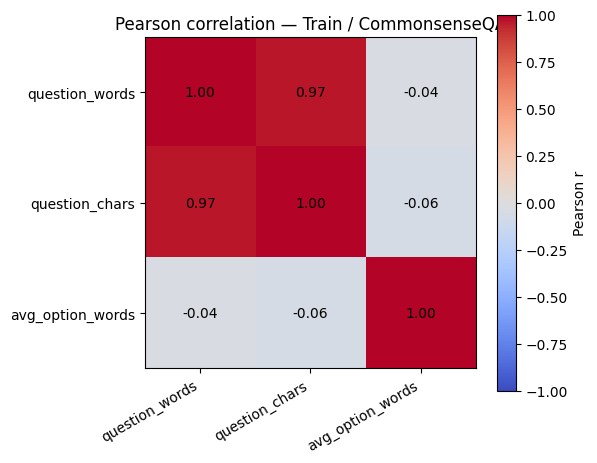

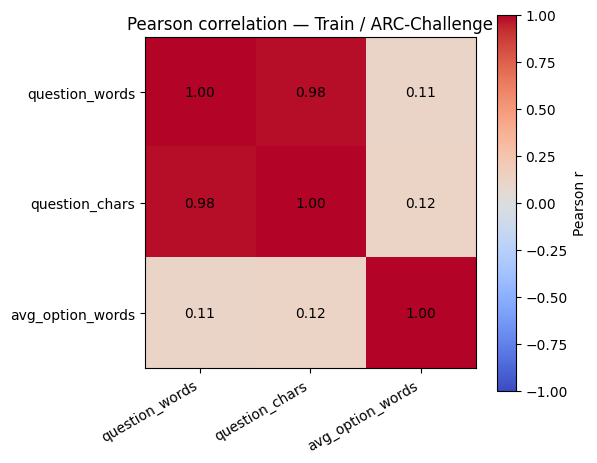

\nPearson interpretation:
question_words vs question_chars: r = 0.9757
question_chars vs avg_option_words: r = 0.3242
question_words vs avg_option_words: r = 0.2833
Strongest linear relationship: question_words and question_chars (r=0.9757).


In [4]:
# ۴. Pearson روی Train

pearson_overall = train_df[FEATURES].corr(method="pearson")
pearson_by_class = {
    name: train_df.loc[train_df["y"] == class_id, FEATURES].corr(method="pearson")
    for class_id, name in CLASS_NAMES.items()
}

print("Pearson — all Train")
display(pearson_overall.round(4))

for class_name, matrix in pearson_by_class.items():
    print(f"Pearson — {class_name}")
    display(matrix.round(4))


def draw_corr_heatmap(corr, title, save_path=None):
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.index)))
    ax.set_xticklabels(corr.columns, rotation=30, ha="right")
    ax.set_yticklabels(corr.index)
    ax.set_title(title)
    for i in range(corr.shape[0]):
        for j in range(corr.shape[1]):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}",
                    ha="center", va="center", fontsize=10)
    fig.colorbar(image, ax=ax, label="Pearson r")
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=170, bbox_inches="tight")
    plt.show()


draw_corr_heatmap(
    pearson_overall,
    "Pearson correlation — Train (all classes)",
    OUTPUT_DIR / "pearson_train_overall.png",
)
for class_name, matrix in pearson_by_class.items():
    safe_name = class_name.lower().replace("-", "_")
    draw_corr_heatmap(
        matrix,
        f"Pearson correlation — Train / {class_name}",
        OUTPUT_DIR / f"pearson_train_{safe_name}.png",
    )

pearson_overall.to_csv(OUTPUT_DIR / "pearson_train_overall.csv")
for class_name, matrix in pearson_by_class.items():
    safe_name = class_name.lower().replace("-", "_")
    matrix.to_csv(OUTPUT_DIR / f"pearson_train_{safe_name}.csv")

pair_values = []
for i, feature_a in enumerate(FEATURES):
    for feature_b in FEATURES[i + 1:]:
        pair_values.append((
            feature_a, feature_b,
            float(pearson_overall.loc[feature_a, feature_b])
        ))
pair_values.sort(key=lambda item: abs(item[2]), reverse=True)

print("\\nPearson interpretation:")
for feature_a, feature_b, value in pair_values:
    print(f"{feature_a} vs {feature_b}: r = {value:.4f}")

strongest_pair = pair_values[0]
print(
    f"Strongest linear relationship: {strongest_pair[0]} and "
    f"{strongest_pair[1]} (r={strongest_pair[2]:.4f})."
)

## ۴. گسسته‌سازی و Conditional Mutual Information

برای ساخت TAN، وابستگی شرطی ویژگی‌ها با CMI سنجیده می‌شود.

**CMI استاندارد تجربی** با وزن فراوانی کلاس‌ها محاسبه می‌شود. برای بررسی اثر عدم‌توازن کلاس‌ها، نسخه میانگین با وزن برابر کلاس‌ها نیز جداگانه گزارش می‌شود؛ نسخه دوم تحلیل حساسیت است و جایگزین تعریف استاندارد CMI نیست.

In [5]:
# ۵. Quantile discretization و توابع CMI

class QuantileDiscretizer:
    def __init__(self, n_bins=3):
        self.n_bins = int(n_bins)
        self.internal_edges_ = {}
        self.n_states_ = {}

    def fit(self, frame, features):
        for feature in features:
            values = pd.to_numeric(frame[feature], errors="coerce").dropna().to_numpy()
            if len(values) == 0:
                raise ValueError(f"No valid values for {feature}.")
            quantiles = np.linspace(0, 1, self.n_bins + 1)
            edges = np.quantile(values, quantiles)
            internal = np.unique(edges[1:-1])
            self.internal_edges_[feature] = internal.astype(float)
            self.n_states_[feature] = len(internal) + 1
        return self

    def transform(self, frame, features):
        transformed = pd.DataFrame(index=frame.index)
        for feature in features:
            values = pd.to_numeric(frame[feature], errors="coerce").to_numpy()
            transformed[feature] = np.digitize(
                values, bins=self.internal_edges_[feature], right=False
            ).astype(int)
        return transformed

    def summary(self):
        return pd.DataFrame([
            {
                "feature": feature,
                "internal_edges": self.internal_edges_[feature].tolist(),
                "number_of_states": self.n_states_[feature],
            }
            for feature in self.internal_edges_
        ])


def mutual_information_discrete(x, z):
    x = np.asarray(x, dtype=int)
    z = np.asarray(z, dtype=int)
    table = pd.crosstab(pd.Series(x), pd.Series(z)).to_numpy(dtype=float)
    if table.sum() == 0:
        return 0.0
    p_xz = table / table.sum()
    p_x = p_xz.sum(axis=1, keepdims=True)
    p_z = p_xz.sum(axis=0, keepdims=True)
    expected = p_x @ p_z
    mask = p_xz > 0
    return float(np.sum(p_xz[mask] * np.log(p_xz[mask] / expected[mask])))


def conditional_mutual_information(x, z, y, weighting="empirical"):
    x = np.asarray(x, dtype=int)
    z = np.asarray(z, dtype=int)
    y = np.asarray(y, dtype=int)
    classes = np.unique(y)

    if weighting == "empirical":
        weights = {c: float(np.mean(y == c)) for c in classes}
    elif weighting == "equal":
        weights = {c: 1.0 / len(classes) for c in classes}
    else:
        raise ValueError("weighting must be 'empirical' or 'equal'")

    result = 0.0
    for class_value in classes:
        mask = y == class_value
        result += weights[class_value] * mutual_information_discrete(
            x[mask], z[mask]
        )
    return float(result)


def cmi_matrix(discrete_frame, y, features, weighting="empirical"):
    result = pd.DataFrame(
        np.zeros((len(features), len(features))),
        index=features,
        columns=features,
        dtype=float,
    )
    y = np.asarray(y, dtype=int)
    for i, feature_a in enumerate(features):
        for j in range(i + 1, len(features)):
            feature_b = features[j]
            value = conditional_mutual_information(
                discrete_frame[feature_a].to_numpy(),
                discrete_frame[feature_b].to_numpy(),
                y,
                weighting=weighting,
            )
            result.loc[feature_a, feature_b] = value
            result.loc[feature_b, feature_a] = value
    return result


def learn_tan_structure(discrete_frame, y, features, weighting="empirical"):
    cmi = cmi_matrix(discrete_frame, y, features, weighting=weighting)

    # Kruskal maximum spanning tree
    edges = []
    for i in range(len(features)):
        for j in range(i + 1, len(features)):
            a, b = features[i], features[j]
            edges.append((float(cmi.loc[a, b]), a, b))
    edges.sort(key=lambda item: (-item[0], item[1], item[2]))

    union_parent = {feature: feature for feature in features}

    def find(node):
        if union_parent[node] != node:
            union_parent[node] = find(union_parent[node])
        return union_parent[node]

    def union(a, b):
        root_a, root_b = find(a), find(b)
        if root_a == root_b:
            return False
        union_parent[root_b] = root_a
        return True

    tree_edges = []
    for weight, feature_a, feature_b in edges:
        if union(feature_a, feature_b):
            tree_edges.append((feature_a, feature_b, weight))
        if len(tree_edges) == len(features) - 1:
            break

    weighted_degree = {feature: 0.0 for feature in features}
    adjacency = {feature: [] for feature in features}
    for a, b, weight in tree_edges:
        weighted_degree[a] += weight
        weighted_degree[b] += weight
        adjacency[a].append((b, weight))
        adjacency[b].append((a, weight))

    root = max(features, key=lambda feature: weighted_degree[feature])
    feature_parent = {feature: None for feature in features}
    visited = {root}
    queue = [root]

    while queue:
        current = queue.pop(0)
        for neighbor, weight in sorted(
            adjacency[current], key=lambda item: item[1], reverse=True
        ):
            if neighbor not in visited:
                visited.add(neighbor)
                feature_parent[neighbor] = current
                queue.append(neighbor)

    return cmi, tree_edges, feature_parent, root


# CMI comparison on Train, with discretization learned from Train only.
initial_discretizer = QuantileDiscretizer(n_bins=3).fit(train_df, FEATURES)
X_train_disc_initial = initial_discretizer.transform(train_df, FEATURES)
y_train = train_df["y"].to_numpy()

cmi_train_standard = cmi_matrix(
    X_train_disc_initial, y_train, FEATURES, weighting="empirical"
)
cmi_train_equal = cmi_matrix(
    X_train_disc_initial, y_train, FEATURES, weighting="equal"
)

print("Standard empirical CMI on Train (nats):")
display(cmi_train_standard.round(4))
print("Equal-class CMI sensitivity analysis on Train (nats):")
display(cmi_train_equal.round(4))

cmi_train_standard.to_csv(OUTPUT_DIR / "cmi_train_standard.csv")
cmi_train_equal.to_csv(OUTPUT_DIR / "cmi_train_equal_class_sensitivity.csv")

Standard empirical CMI on Train (nats):


,question_words,question_chars,avg_option_words
question_words,0.0000,0.5989,0.0017
question_chars,0.5989,0.0000,0.0035
avg_option_words,0.0017,0.0035,0.0000


Equal-class CMI sensitivity analysis on Train (nats):


,question_words,question_chars,avg_option_words
question_words,0.0000,0.5901,0.0058
question_chars,0.5901,0.0000,0.0089
avg_option_words,0.0058,0.0089,0.0000


## ۵. ساختار شبکه بیزی TAN

در TAN:
- گره کلاس \(Y\) والد تمام ویژگی‌هاست.
- بین ویژگی‌ها یک درخت بیشینه ساخته می‌شود.
- یال‌های درخت با بیشینه‌کردن CMI استاندارد انتخاب می‌شوند.

این ساختار از NBC عمومی‌تر است؛ چون استقلال کامل همه ویژگی‌ها را به شرط کلاس تحمیل نمی‌کند. جهت‌دهی یال‌های ویژگی‌ها برای ساخت یک DAG انجام می‌شود و به‌تنهایی معنای علی ندارد.

In [6]:
# ۶. طبقه‌بند TAN با Laplace Smoothing

class TANClassifier:
    def __init__(
        self, features, feature_parents, n_states,
        alpha=1.0, prior_mode="balanced"
    ):
        self.features = list(features)
        self.feature_parents = dict(feature_parents)
        self.n_states = dict(n_states)
        self.alpha = float(alpha)
        self.prior_mode = prior_mode

    def fit(self, X, y):
        X = X[self.features].astype(int).reset_index(drop=True)
        y = np.asarray(y, dtype=int)
        self.classes_ = np.sort(np.unique(y))

        if len(self.classes_) < 2:
            raise ValueError("At least two classes are required.")

        if self.prior_mode == "balanced":
            self.class_prior_ = {
                int(c): 1.0 / len(self.classes_) for c in self.classes_
            }
        elif self.prior_mode == "empirical":
            counts = pd.Series(y).value_counts(normalize=True).to_dict()
            self.class_prior_ = {int(c): float(counts[c]) for c in self.classes_}
        else:
            raise ValueError("prior_mode must be 'balanced' or 'empirical'")

        self.cpts_ = {}

        for feature in self.features:
            child_states = int(self.n_states[feature])
            parent_feature = self.feature_parents.get(feature)

            if parent_feature is None:
                for class_value in self.classes_:
                    class_mask = y == class_value
                    counts = np.bincount(
                        X.loc[class_mask, feature].to_numpy(),
                        minlength=child_states,
                    ).astype(float)
                    probabilities = (
                        counts + self.alpha
                    ) / (
                        counts.sum() + self.alpha * child_states
                    )
                    self.cpts_[(feature, int(class_value))] = probabilities

            else:
                parent_states = int(self.n_states[parent_feature])
                table = np.zeros(
                    (len(self.classes_), parent_states, child_states),
                    dtype=float,
                )
                for class_index, class_value in enumerate(self.classes_):
                    class_mask = y == class_value
                    parent_values = X.loc[class_mask, parent_feature].to_numpy()
                    child_values = X.loc[class_mask, feature].to_numpy()

                    for parent_state in range(parent_states):
                        state_mask = parent_values == parent_state
                        counts = np.bincount(
                            child_values[state_mask],
                            minlength=child_states,
                        ).astype(float)
                        probabilities = (
                            counts + self.alpha
                        ) / (
                            counts.sum() + self.alpha * child_states
                        )
                        table[class_index, parent_state, :] = probabilities

                for class_index, class_value in enumerate(self.classes_):
                    self.cpts_[(feature, int(class_value))] = table[class_index]

        return self

    def predict_log_proba(self, X):
        X = X[self.features].astype(int).reset_index(drop=True)
        log_scores = np.zeros((len(X), len(self.classes_)), dtype=float)

        for class_index, class_value in enumerate(self.classes_):
            log_scores[:, class_index] = np.log(
                self.class_prior_[int(class_value)]
            )
            for feature in self.features:
                child_values = X[feature].to_numpy()
                parent_feature = self.feature_parents.get(feature)
                cpt = self.cpts_[(feature, int(class_value))]

                if parent_feature is None:
                    probabilities = cpt[child_values]
                else:
                    parent_values = X[parent_feature].to_numpy()
                    probabilities = cpt[parent_values, child_values]

                log_scores[:, class_index] += np.log(probabilities)

        row_max = log_scores.max(axis=1, keepdims=True)
        log_normalizer = row_max + np.log(
            np.exp(log_scores - row_max).sum(axis=1, keepdims=True)
        )
        return log_scores - log_normalizer

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_log_proba(X), axis=1)]


def calculate_metrics(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1,
    }


def fit_nbc(X_train_disc, y_train, features, n_states, prior_mode="balanced"):
    no_feature_parents = {feature: None for feature in features}
    return TANClassifier(
        features=features,
        feature_parents=no_feature_parents,
        n_states=n_states,
        alpha=ALPHA,
        prior_mode=prior_mode,
    ).fit(X_train_disc, y_train)

## ۶. انتخاب تعداد بازه‌ها و بررسی prior با Validation

برای هر تعداد بازه، BBN/TAN و NBC با دو نوع prior آزمایش می‌شوند:
- `balanced`: احتمال پیشین برابر برای دو کلاس
- `empirical`: احتمال پیشین متناسب با فراوانی کلاس‌ها در Train

**قاعده انتخاب:** تعداد بازه‌ها برای مدل اصلی TAN بر اساس Macro F1 روی Validation و با prior متوازن انتخاب می‌شود. prior تجربی فقط برای تحلیل حساسیت گزارش می‌شود؛ چون هدف این آزمایش مقایسه دو دامنه با وزن برابر است.

In [7]:
# ۷. مقایسه مدل‌ها و priorها فقط روی Validation

validation_rows = []
validation_candidates = {}

for n_bins in N_BINS_CANDIDATES:
    discretizer = QuantileDiscretizer(n_bins=n_bins).fit(train_df, FEATURES)
    Xtr_disc = discretizer.transform(train_df, FEATURES)
    Xval_disc = discretizer.transform(val_df, FEATURES)
    ytr = train_df["y"].to_numpy()
    yval = val_df["y"].to_numpy()

    cmi, tree_edges, parents, root = learn_tan_structure(
        Xtr_disc, ytr, FEATURES, weighting="empirical"
    )

    for prior_mode in ["balanced", "empirical"]:
        bbn = TANClassifier(
            FEATURES, parents, discretizer.n_states_,
            alpha=ALPHA, prior_mode=prior_mode
        ).fit(Xtr_disc, ytr)
        bbn_pred = bbn.predict(Xval_disc)

        nbc = fit_nbc(
            Xtr_disc, ytr, FEATURES, discretizer.n_states_,
            prior_mode=prior_mode
        )
        nbc_pred = nbc.predict(Xval_disc)

        validation_rows.append({
            "n_bins": n_bins,
            "model": "BBN_TAN",
            "prior": prior_mode,
            **calculate_metrics(yval, bbn_pred),
        })
        validation_rows.append({
            "n_bins": n_bins,
            "model": "NBC",
            "prior": prior_mode,
            **calculate_metrics(yval, nbc_pred),
        })

        validation_candidates[(n_bins, prior_mode, "BBN_TAN")] = {
            "discretizer": discretizer,
            "model": bbn,
            "cmi": cmi,
            "edges": tree_edges,
            "parents": parents,
            "root": root,
        }
        validation_candidates[(n_bins, prior_mode, "NBC")] = {
            "discretizer": discretizer,
            "model": nbc,
        }

validation_results = pd.DataFrame(validation_rows)
display(
    validation_results.sort_values(
        ["model", "prior", "macro_f1"],
        ascending=[True, True, False],
    ).round(4)
)
validation_results.to_csv(
    OUTPUT_DIR / "validation_prior_and_bins_comparison.csv",
    index=False,
)

# Primary model selection: BBN/TAN with balanced prior.
bbn_balanced_rows = validation_results[
    (validation_results["model"] == "BBN_TAN")
    & (validation_results["prior"] == "balanced")
]
best_row = bbn_balanced_rows.sort_values(
    ["macro_f1", "balanced_accuracy"],
    ascending=False,
).iloc[0]
BEST_N_BINS = int(best_row["n_bins"])

print("Selected n_bins for primary BBN/TAN:", BEST_N_BINS)
print("Validation Macro F1:", round(float(best_row["macro_f1"]), 4))

print("\\nPrior sensitivity at selected n_bins:")
display(
    validation_results[
        (validation_results["n_bins"] == BEST_N_BINS)
    ].sort_values(["model", "prior"]).round(4)
)

,n_bins,model,prior,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
4,3,BBN_TAN,balanced,0.8230,0.7825,0.7310,0.7825,0.7496
8,4,BBN_TAN,balanced,0.7868,0.7966,0.7100,0.7966,0.7274
0,2,BBN_TAN,balanced,0.7928,0.7599,0.7002,0.7599,0.7179
10,4,BBN_TAN,empirical,0.8684,0.7312,0.8157,0.7312,0.7614
2,2,BBN_TAN,empirical,0.8033,0.5000,0.4016,0.5000,0.4455
6,3,BBN_TAN,empirical,0.8033,0.5000,0.4016,0.5000,0.4455
9,4,NBC,balanced,0.8007,0.7560,0.7047,0.7560,0.7219
1,2,NBC,balanced,0.7743,0.7497,0.6851,0.7497,0.7010
5,3,NBC,balanced,0.7789,0.7273,0.6793,0.7273,0.6943
7,3,NBC,empirical,0.8612,0.7431,0.7889,0.7431,0.7621


Selected n_bins for primary BBN/TAN: 3
Validation Macro F1: 0.7496
\nPrior sensitivity at selected n_bins:


,n_bins,model,prior,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
4,3,BBN_TAN,balanced,0.8230,0.7825,0.7310,0.7825,0.7496
6,3,BBN_TAN,empirical,0.8033,0.5000,0.4016,0.5000,0.4455
5,3,NBC,balanced,0.7789,0.7273,0.6793,0.7273,0.6943
7,3,NBC,empirical,0.8612,0.7431,0.7889,0.7431,0.7621


## ۷. تحلیل حساسیت ویژگی‌های بسیار همبسته

در Pearson مشاهده شد که `question_words` و `question_chars` همبستگی خطی بالایی دارند. در این بخش، روی Validation بررسی می‌کنیم حذف هرکدام چه اثری روی Macro F1 مدل TAN دارد. این تحلیل فقط حساسیت مدل را نشان می‌دهد و نتیجه Test را برای انتخاب ویژگی‌ها به کار نمی‌گیرد.

In [8]:
# ۸. Feature ablation روی Validation

feature_sets = {
    "all_3_features": FEATURES,
    "without_question_words": [
        "question_chars", "avg_option_words"
    ],
    "without_question_chars": [
        "question_words", "avg_option_words"
    ],
}

ablation_rows = []
ytr = train_df["y"].to_numpy()
yval = val_df["y"].to_numpy()

for set_name, selected_features in feature_sets.items():
    discretizer = QuantileDiscretizer(n_bins=BEST_N_BINS).fit(
        train_df, selected_features
    )
    Xtr_disc = discretizer.transform(train_df, selected_features)
    Xval_disc = discretizer.transform(val_df, selected_features)

    _, edges, parents, root = learn_tan_structure(
        Xtr_disc, ytr, selected_features, weighting="empirical"
    )
    model = TANClassifier(
        selected_features, parents, discretizer.n_states_,
        alpha=ALPHA, prior_mode=FINAL_PRIOR_MODE
    ).fit(Xtr_disc, ytr)

    pred = model.predict(Xval_disc)
    ablation_rows.append({
        "feature_set": set_name,
        "features": ", ".join(selected_features),
        **calculate_metrics(yval, pred),
    })

ablation_results = pd.DataFrame(ablation_rows)
display(ablation_results.round(4))
ablation_results.to_csv(
    OUTPUT_DIR / "validation_feature_ablation.csv",
    index=False,
)

,feature_set,features,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,all_3_features,"question_words, question_chars, avg_option_words",0.8230,0.7825,0.7310,0.7825,0.7496
1,without_question_words,"question_chars, avg_option_words",0.8066,0.7748,0.7150,0.7748,0.7340
2,without_question_chars,"question_words, avg_option_words",0.7395,0.7696,0.6797,0.7696,0.6846


## ۸. آموزش نهایی و ارزیابی Test

پس از انتخاب تعداد بازه‌ها، مرزهای گسسته‌سازی و ساختار TAN با Train + Validation دوباره یاد گرفته می‌شوند. مدل اصلی و baseline با prior متوازن برازش می‌شوند. Test فقط برای ارزیابی نهایی استفاده می‌شود.

In [9]:
# ۹. آموزش نهایی BBN/TAN و NBC

train_validation_df = pd.concat(
    [train_df, val_df], axis=0, ignore_index=True
)
y_trainval = train_validation_df["y"].to_numpy()
y_test = test_df["y"].to_numpy()

final_discretizer = QuantileDiscretizer(
    n_bins=BEST_N_BINS
).fit(train_validation_df, FEATURES)

X_trainval_disc = final_discretizer.transform(
    train_validation_df, FEATURES
)
X_test_disc = final_discretizer.transform(test_df, FEATURES)

# CMI استاندارد برای ساخت TAN
final_cmi_standard, final_edges, final_parents, final_root = learn_tan_structure(
    X_trainval_disc,
    y_trainval,
    FEATURES,
    weighting="empirical",
)

# CMI با وزن برابر کلاس‌ها فقط برای تحلیل حساسیت
final_cmi_equal = cmi_matrix(
    X_trainval_disc,
    y_trainval,
    FEATURES,
    weighting="equal",
)
_, equal_edges, equal_parents, equal_root = learn_tan_structure(
    X_trainval_disc,
    y_trainval,
    FEATURES,
    weighting="equal",
)

final_bbn = TANClassifier(
    FEATURES,
    final_parents,
    final_discretizer.n_states_,
    alpha=ALPHA,
    prior_mode=FINAL_PRIOR_MODE,
).fit(X_trainval_disc, y_trainval)

final_nbc = fit_nbc(
    X_trainval_disc,
    y_trainval,
    FEATURES,
    final_discretizer.n_states_,
    prior_mode=FINAL_PRIOR_MODE,
)

bbn_test_pred = final_bbn.predict(X_test_disc)
nbc_test_pred = final_nbc.predict(X_test_disc)

bbn_test_metrics = calculate_metrics(y_test, bbn_test_pred)
nbc_test_metrics = calculate_metrics(y_test, nbc_test_pred)

test_metrics = pd.DataFrame([
    {"model": "BBN_TAN (primary)", **bbn_test_metrics},
    {"model": "NBC (baseline)", **nbc_test_metrics},
])
display(test_metrics.round(4))
test_metrics.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)

print("Final TAN root:", final_root)
print("Final TAN feature parents:", final_parents)
print("Final TAN edges (standard empirical CMI):")
for edge in final_edges:
    print(edge)

print("\\nFinal CMI — standard empirical weighting:")
display(final_cmi_standard.round(4))
print("Final CMI — equal-class sensitivity:")
display(final_cmi_equal.round(4))

print("\\nTree from equal-class sensitivity CMI:")
print("Root:", equal_root)
print("Parents:", equal_parents)
print("Edges:", equal_edges)

final_cmi_standard.to_csv(
    OUTPUT_DIR / "cmi_train_validation_standard.csv"
)
final_cmi_equal.to_csv(
    OUTPUT_DIR / "cmi_train_validation_equal_class_sensitivity.csv"
)
final_discretizer.summary().to_csv(
    OUTPUT_DIR / "final_discretization_edges.csv",
    index=False,
)

,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,BBN_TAN (primary),0.7768,0.7777,0.7818,0.7777,0.7762
1,NBC (baseline),0.7266,0.7275,0.7305,0.7275,0.7259


Final TAN root: question_chars
Final TAN feature parents: {'question_words': 'question_chars', 'question_chars': None, 'avg_option_words': 'question_chars'}
Final TAN edges (standard empirical CMI):
('question_words', 'question_chars', 0.5968689858699966)
('question_chars', 'avg_option_words', 0.0029094888953395542)
\nFinal CMI — standard empirical weighting:


,question_words,question_chars,avg_option_words
question_words,0.0000,0.5969,0.0015
question_chars,0.5969,0.0000,0.0029
avg_option_words,0.0015,0.0029,0.0000


Final CMI — equal-class sensitivity:


,question_words,question_chars,avg_option_words
question_words,0.0000,0.5863,0.005
question_chars,0.5863,0.0000,0.007
avg_option_words,0.0050,0.0070,0.000


\nTree from equal-class sensitivity CMI:
Root: question_chars
Parents: {'question_words': 'question_chars', 'question_chars': None, 'avg_option_words': 'question_chars'}
Edges: [('question_words', 'question_chars', 0.5862852345961158), ('question_chars', 'avg_option_words', 0.006960577162491798)]


## ۹. Confusion Matrix و گزارش طبقه‌بندی

در ماتریس درهم‌ریختگی، سطرها کلاس واقعی و ستون‌ها کلاس پیش‌بینی‌شده هستند. معیارهای Accuracy، Balanced Accuracy، Macro Precision، Macro Recall و Macro F1 برای هر دو مدل گزارش می‌شوند.

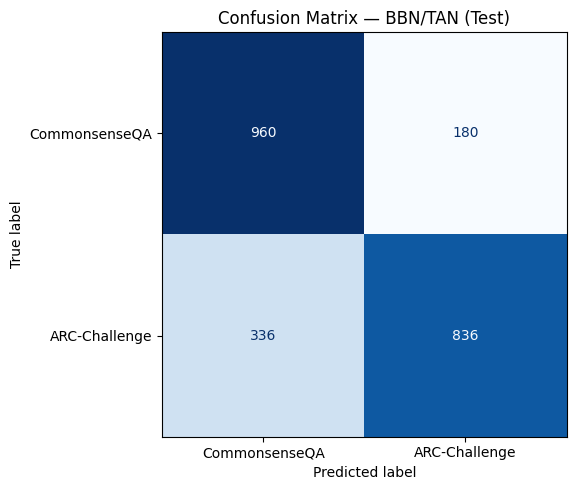

Classification report — BBN/TAN
               precision    recall  f1-score   support

CommonsenseQA     0.7407    0.8421    0.7882      1140
ARC-Challenge     0.8228    0.7133    0.7642      1172

     accuracy                         0.7768      2312
    macro avg     0.7818    0.7777    0.7762      2312
 weighted avg     0.7824    0.7768    0.7760      2312



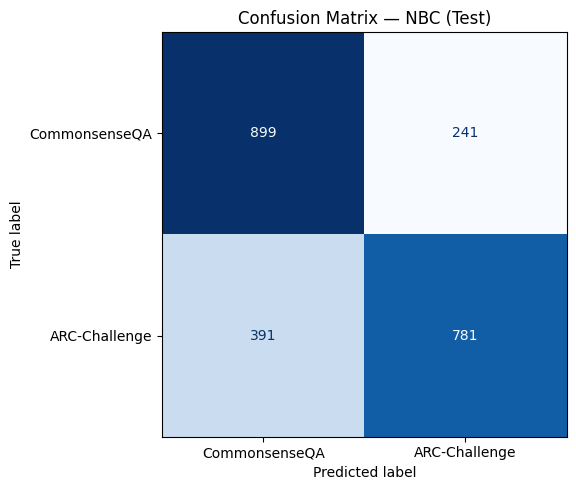

Classification report — NBC
               precision    recall  f1-score   support

CommonsenseQA     0.6969    0.7886    0.7399      1140
ARC-Challenge     0.7642    0.6664    0.7119      1172

     accuracy                         0.7266      2312
    macro avg     0.7305    0.7275    0.7259      2312
 weighted avg     0.7310    0.7266    0.7257      2312



In [10]:
# ۱۰. Confusion Matrix و Classification Report

def show_confusion_matrix(y_true, y_pred, model_name, file_stem):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(6, 5))
    display_plot = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[CLASS_NAMES[0], CLASS_NAMES[1]],
    )
    display_plot.plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False
    )
    ax.set_title(f"Confusion Matrix — {model_name} (Test)")
    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / f"confusion_matrix_{file_stem}.png",
        dpi=170, bbox_inches="tight"
    )
    plt.show()

    pd.DataFrame(
        cm,
        index=["Actual_CSQA", "Actual_ARC"],
        columns=["Predicted_CSQA", "Predicted_ARC"],
    ).to_csv(OUTPUT_DIR / f"confusion_matrix_{file_stem}.csv")

    print(f"Classification report — {model_name}")
    report = classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=[CLASS_NAMES[0], CLASS_NAMES[1]],
        zero_division=0,
        digits=4,
        output_dict=True,
    )
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=[CLASS_NAMES[0], CLASS_NAMES[1]],
        zero_division=0,
        digits=4,
    ))
    pd.DataFrame(report).transpose().to_csv(
        OUTPUT_DIR / f"classification_report_{file_stem}.csv"
    )
    return cm


cm_bbn = show_confusion_matrix(
    y_test, bbn_test_pred, "BBN/TAN", "bbn_tan"
)
cm_nbc = show_confusion_matrix(
    y_test, nbc_test_pred, "NBC", "nbc"
)

## ۱۰. نمایش ساختار نهایی TAN و خلاصه نتایج

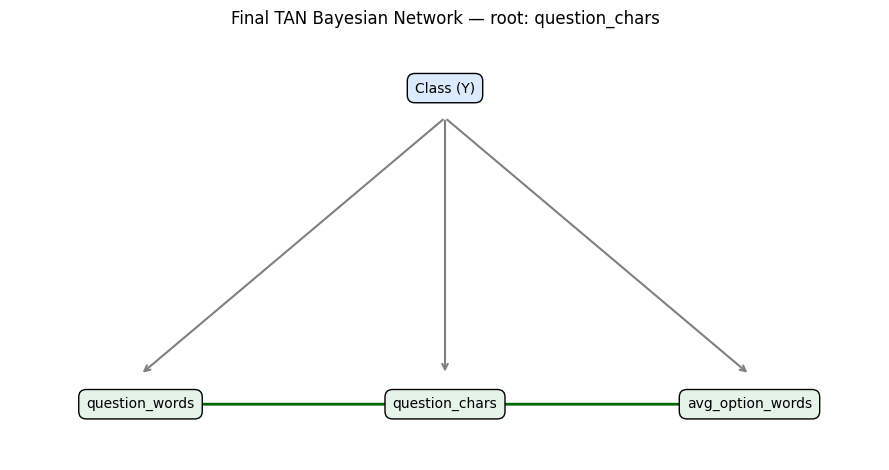

Final discretization:


,feature,internal_edges,number_of_states
0,question_words,"[10.0, 15.0]",3
1,question_chars,"[55.0, 80.0]",3
2,avg_option_words,"[1.4, 1.8]",3


In [11]:
# ۱۱. رسم ساختار نهایی TAN

def plot_tan_structure(features, feature_parents, root, save_path=None):
    positions = {"Class": (0.5, 1.0)}
    if len(features) == 3:
        positions[features[0]] = (0.15, 0.15)
        positions[features[1]] = (0.50, 0.15)
        positions[features[2]] = (0.85, 0.15)
    else:
        xs = np.linspace(0.1, 0.9, len(features))
        for feature, x in zip(features, xs):
            positions[feature] = (float(x), 0.15)

    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.15)
    ax.axis("off")

    for feature in features:
        x1, y1 = positions["Class"]
        x2, y2 = positions[feature]
        ax.annotate(
            "", xy=(x2, y2 + 0.08), xytext=(x1, y1 - 0.08),
            arrowprops=dict(arrowstyle="->", lw=1.5, color="gray"),
        )

    for child, parent_feature in feature_parents.items():
        if parent_feature is not None:
            x1, y1 = positions[parent_feature]
            x2, y2 = positions[child]
            ax.annotate(
                "", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", lw=2.0, color="darkgreen"),
            )

    for node, (x, y) in positions.items():
        if node == "Class":
            face, label = "#DCEAFE", "Class (Y)"
        else:
            face, label = "#E5F3E8", node
        ax.text(
            x, y, label, ha="center", va="center",
            bbox=dict(
                boxstyle="round,pad=0.55",
                facecolor=face, edgecolor="black"
            ),
            fontsize=10,
        )

    ax.set_title(f"Final TAN Bayesian Network — root: {root}")
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=170, bbox_inches="tight")
    plt.show()


plot_tan_structure(
    FEATURES, final_parents, final_root,
    OUTPUT_DIR / "final_tan_network.png"
)

print("Final discretization:")
display(final_discretizer.summary())

## ۱۱. نتیجه‌گیری قابل استفاده در گزارش

پس از اجرا، اعداد واقعی از خروجی همین نوت‌بوک برداشته شوند. در تفسیر نهایی باید سه نکته رعایت شود:

- Pearson همبستگی خطی را نشان می‌دهد و به‌تنهایی استقلال شرطی را ثابت نمی‌کند.
- TAN وابستگی بین ویژگی‌ها را با استفاده از CMI مدل می‌کند؛ NBC baseline فرض استقلال شرطی ویژگی‌ها را دارد.
- خروجی این آزمایش فقط طبقه‌بندی منبع دیتاست است و نباید به‌عنوان دقت تشخیص Silent Failure معرفی شود.

In [12]:
# ۱۲. ذخیره خلاصه نهایی و خروجی‌ها

summary = {
    "task": "dataset_source_classification",
    "class_mapping": {
        "0": "CommonsenseQA",
        "1": "ARC-Challenge",
    },
    "features": FEATURES,
    "excluded_feature": "option_count",
    "primary_classifier": "Bayesian Belief Network — TAN",
    "baseline_classifier": "Naive Bayes Classifier",
    "selected_n_bins": int(BEST_N_BINS),
    "laplace_alpha": float(ALPHA),
    "final_prior_mode": FINAL_PRIOR_MODE,
    "cmi_structure_weighting": "empirical_class_frequency",
    "cmi_equal_class_sensitivity_available": True,
    "final_root_feature": final_root,
    "final_feature_parents": final_parents,
    "final_tree_edges": [
        {
            "feature_a": a,
            "feature_b": b,
            "conditional_mutual_information_nats": float(weight),
        }
        for a, b, weight in final_edges
    ],
    "test_metrics": {
        "BBN_TAN": {k: float(v) for k, v in bbn_test_metrics.items()},
        "NBC": {k: float(v) for k, v in nbc_test_metrics.items()},
    },
    "note": (
        "This notebook classifies dataset source (CommonsenseQA vs ARC-Challenge). "
        "It does not detect LLM correctness or Silent Failure."
    ),
}

with open(OUTPUT_DIR / "classification_summary.json", "w", encoding="utf-8") as file:
    json.dump(summary, file, ensure_ascii=False, indent=2)

print("All outputs saved to:")
print(OUTPUT_DIR)

print("\\nFinal result — BBN/TAN")
for metric, value in bbn_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\\nFinal result — NBC")
for metric, value in nbc_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print(
    "\\nReminder: this result measures dataset-source classification only; "
    "it is not a Silent Failure detection score."
)

if IN_COLAB:
    zip_path = Path("/content/classification_v3_results.zip")
    shutil.make_archive(
        str(zip_path.with_suffix("")),
        "zip",
        OUTPUT_DIR,
    )
    print(f"Results ZIP created: {zip_path}")

All outputs saved to:
D:\app\ai\Detecting Silent Failures of Uncertainty Estimators\outputs\classification_v3
\nFinal result — BBN/TAN
accuracy: 0.7768
balanced_accuracy: 0.7777
macro_precision: 0.7818
macro_recall: 0.7777
macro_f1: 0.7762
\nFinal result — NBC
accuracy: 0.7266
balanced_accuracy: 0.7275
macro_precision: 0.7305
macro_recall: 0.7275
macro_f1: 0.7259
\nReminder: this result measures dataset-source classification only; it is not a Silent Failure detection score.
